# UK Historic Weather Trends: Seasonal Regression and Bootstrap Analysis


## Author

**Abdallah Ramadan**


## Project overview

This project investigates long-term patterns in monthly UK weather records from 37 stations. It estimates maximum-temperature trends, compares geographical variation, constructs residual-bootstrap intervals, explores model-based August 2075 extrapolations, and examines frost occurrence over time.

The analysis describes statistical patterns in the available station records. It does not, by itself, establish causal climate attribution.


# 1 Setup

Import the required libraries, configure plotting, and locate the repository data snapshot.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

plt.style.use("default")
plt.rcParams["figure.figsize"] = (8, 4)

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data").exists():
    raise RuntimeError("Run this notebook from the repository root or notebooks directory.")

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "weather_data"
stations_meta_path = DATA_DIR / "ALL-WEATHER-STATIONS.csv"

if not stations_meta_path.exists():
    raise FileNotFoundError(f"Station metadata not found: {stations_meta_path}")

stations_meta = pd.read_csv(stations_meta_path)
print(f"Data directory: {DATA_DIR.relative_to(PROJECT_ROOT)}")
print(f"Stations in metadata: {len(stations_meta)}")
stations_meta.head()


Data directory: data/raw/weather_data
Stations in metadata: 37


,Name,Longnitude,Latitude,Opened,Latest,FileName
0,Aberporth,-4.570,52.139,1941,2025,aberporthdata
1,Armagh,-6.649,54.352,1853,2025,armaghdata
2,Ballypatrick Forest,-6.153,55.181,1961,2025,ballypatrickdata
3,Bradford,-1.772,53.813,1908,2025,bradforddata
4,Braemar No 2,-3.396,57.011,1959,2025,braemardata


# 2 Data loading and validation

- Load ALL-WEATHER-STATIONS
- Load all 37 station datasets
- Combine into a single DataFrame with a station identifier
- Quick Checks:
  - Total dataset size
  - Number of stations
  - Variable completeness (missing values)
  - data range and station coverage

## 2.1 Load station metadata

In [2]:
# List all CSV files in the folder
# A list containing 38 files (1 metadata + 37 station files).

all_csv_files = sorted(DATA_DIR.glob("*.csv"))
len(all_csv_files), [path.name for path in all_csv_files]


(38,
 ['ALL-WEATHER-STATIONS.csv',
  'aberporthdata.csv',
  'armaghdata.csv',
  'ballypatrickdata.csv',
  'bradforddata.csv',
  'braemardata.csv',
  'cambornedata.csv',
  'cambridgedata.csv',
  'cardiffdata.csv',
  'chivenordata.csv',
  'cwmystwythdata.csv',
  'dunstaffnagedata.csv',
  'durhamdata.csv',
  'eastbournedata.csv',
  'eskdalemuirdata.csv',
  'heathrowdata.csv',
  'hurndata.csv',
  'lerwickdata.csv',
  'leucharsdata.csv',
  'lowestoftdata.csv',
  'manstondata.csv',
  'nairndata.csv',
  'newtonriggdata.csv',
  'oxforddata.csv',
  'paisleydata.csv',
  'ringwaydata.csv',
  'rossonwyedata.csv',
  'shawburydata.csv',
  'sheffielddata.csv',
  'southamptondata.csv',
  'stornowaydata.csv',
  'suttonboningtondata.csv',
  'tireedata.csv',
  'valleydata.csv',
  'waddingtondata.csv',
  'whitbydata.csv',
  'wickairportdata.csv',
  'yeoviltondata.csv'])

## 2.2 Discover station files

In [3]:
#List all CSV files and exclude metadata
weather_files = [f for f in all_csv_files if f.name != "ALL-WEATHER-STATIONS.csv"]

len(weather_files), [path.name for path in weather_files[:5]]


(37,
 ['aberporthdata.csv',
  'armaghdata.csv',
  'ballypatrickdata.csv',
  'bradforddata.csv',
  'braemardata.csv'])

## 2.3 Combine station data

In [4]:
weather_dfs = []
for path in weather_files:
    df = pd.read_csv(path)
    df["station_file"] = path.stem
    weather_dfs.append(df)

weather = pd.concat(weather_dfs, ignore_index=True)

weather


,Year,Month,TMax,TMin,Frost,Rainfall,Sunshine,Status,station_file
0,1941,1,NaN,NaN,NaN,74.7,NaN,Confirmed,aberporthdata
1,1941,2,NaN,NaN,NaN,69.1,NaN,Confirmed,aberporthdata
2,1941,3,NaN,NaN,NaN,76.2,NaN,Confirmed,aberporthdata
3,1941,4,NaN,NaN,NaN,33.7,NaN,Confirmed,aberporthdata
4,1941,5,NaN,NaN,NaN,51.3,NaN,Confirmed,aberporthdata
...,...,...,...,...,...,...,...,...,...
39422,2025,5,20.4,8.2,0.0,17.6,239.9,Provisional,yeoviltondata
39423,2025,6,22.9,12.8,0.0,31.0,196.3,Provisional,yeoviltondata
39424,2025,7,24.8,13.6,0.0,36.4,227.2,Provisional,yeoviltondata
39425,2025,8,24.0,12.1,0.0,31.2,193.7,Provisional,yeoviltondata


## 2.4 Data quality checks

Before starting the analysis, we verify that the data has loaded correctly.
We check:
- total dataset size  
- number of stations  
- variable completeness (missing values)  
- date range and station coverage  

### 2.4.1 Dataset dimensions

In [5]:
# Overall dataset dimensions
weather.shape


(39427, 9)

### 2.4.2 Number of stations

In [6]:
weather["station_file"].nunique()

37

### 2.4.3 Station coverage
To see which stations have long vs short histories.

In [7]:
weather["station_file"].value_counts()

station_file
oxforddata             2073
armaghdata             2073
stornowaydata          1827
durhamdata             1749
southamptondata        1743
sheffielddata          1713
bradforddata           1413
eskdalemuirdata        1377
wickairportdata        1341
tireedata              1173
lowestoftdata          1150
lerwickdata            1138
valleydata             1138
rossonwyedata          1138
aberporthdata          1017
manstondata            1011
nairndata              1008
shawburydata            957
waddingtondata          945
heathrowdata            933
chivenordata            837
hurndata                825
leucharsdata            825
newtonriggdata          801
eastbournedata          801
cambridgedata           801
suttonboningtondata     801
braemardata             801
ballypatrickdata        771
whitbydata              769
yeoviltondata           733
ringwaydata             706
dunstaffnagedata        652
paisleydata             627
cwmystwythdata          618
cardiff

### 2.4.4 Missingness by variable

In [8]:
weather.isna().sum()

Year               0
Month              0
TMax             928
TMin             902
Frost           2327
Rainfall         873
Sunshine        9258
Status             0
station_file       0
dtype: int64

***Summary of the Missing Values:***
The dataset contains varying levels of missingness across variables. Year, Month, Station identifier are fully complete, confirming that the dataset is structurally sound. Temperature variables (TMax, TMin) and Rainfall have only small numbers of missing values, mostly in early years before systematic recording began.

Frost and especially Sunshine exhibit substantial missingness. Frost records are absent for many early decades for some stations, while Sunshine measurements show the highest missingness. This is expected because many weather stations only began using sunshine recorders after the mid-20th century.

For Task 1, variables with strong long-term completeness (TMax, Rainfall, Frost) are preferable for descriptive trend analysis. So, our dataset is loaded, the combined one is ready; the missingness is also understood.

*Now we are ready to start task one.*

# 3 Exploratory station comparison

**Aim:**
This task aims to explore qualitative evidence of changes in climate over time.

We focus on three weather measurments:

- **Tempreature** (monthly average daily maximum, 'TMax')
- **Rainfall** ('Rainfall')
- **Frost days** ('Frost')

We illustrate pattrerns using a small number of stations at diverse locations in the uk. We will choose "heathrowdata", "lerwickdata", and "braemardata".

The aim is descriptive: we use plots and tables rather than formal statistical tests here.

## 3.1 Select geographically diverse stations

In [9]:
selected_stations = ["heathrowdata", "lerwickdata", "braemardata"]

df_task1 = weather[weather["station_file"].isin(selected_stations)].copy()

df_task1


,Year,Month,TMax,TMin,Frost,Rainfall,Sunshine,Status,station_file
5274,1959,1,1.7,-5.7,27.0,NaN,34.2,Confirmed,braemardata
5275,1959,2,6.2,-3.2,15.0,NaN,68.6,Confirmed,braemardata
5276,1959,3,7.6,0.8,7.0,NaN,80.9,Confirmed,braemardata
5277,1959,4,NaN,NaN,NaN,NaN,105.0,Confirmed,braemardata
5278,1959,5,15.6,4.6,1.0,NaN,182.6,Confirmed,braemardata
...,...,...,...,...,...,...,...,...,...
16943,2025,5,12.0,6.7,0.0,65.6,231.2,Provisional,lerwickdata
16944,2025,6,13.7,9.1,0.0,91.4,156.1,Provisional,lerwickdata
16945,2025,7,17.2,12.2,0.0,35.2,186.9,Provisional,lerwickdata
16946,2025,8,15.6,11.1,0.0,94.8,135.3,Provisional,lerwickdata


## 3.2 Visualise temperature, rainfall and frost

In [10]:
df_task1["time"] = df_task1["Year"] + (df_task1["Month"] - 1) / 12

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_variable(df, variable, stations):
    plt.figure(figsize=(12, 5))
    for st in stations:
        sub = df[df["station_file"] == st]
        plt.plot(sub["time"], sub[variable], label=st)
    plt.title(f"{variable} Over Time for Three Stations")
    plt.xlabel("Year")
    plt.ylabel(variable)
    plt.legend()
    plt.show()


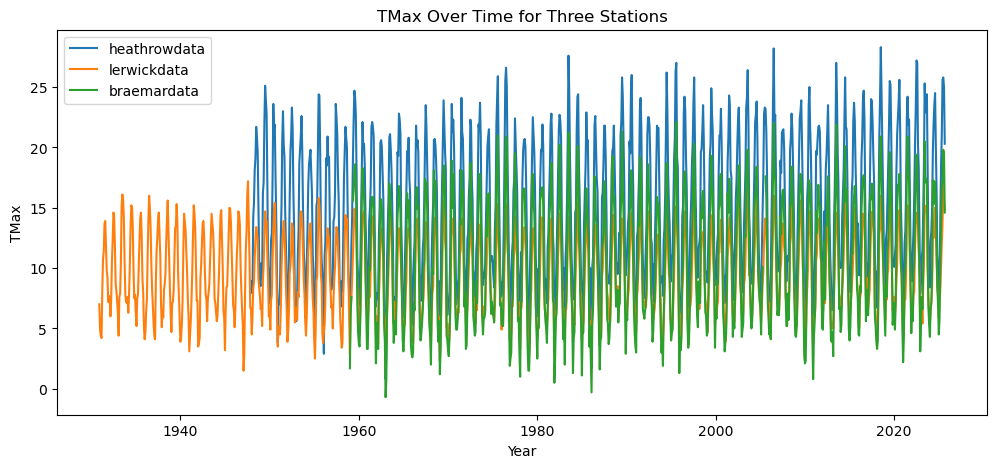

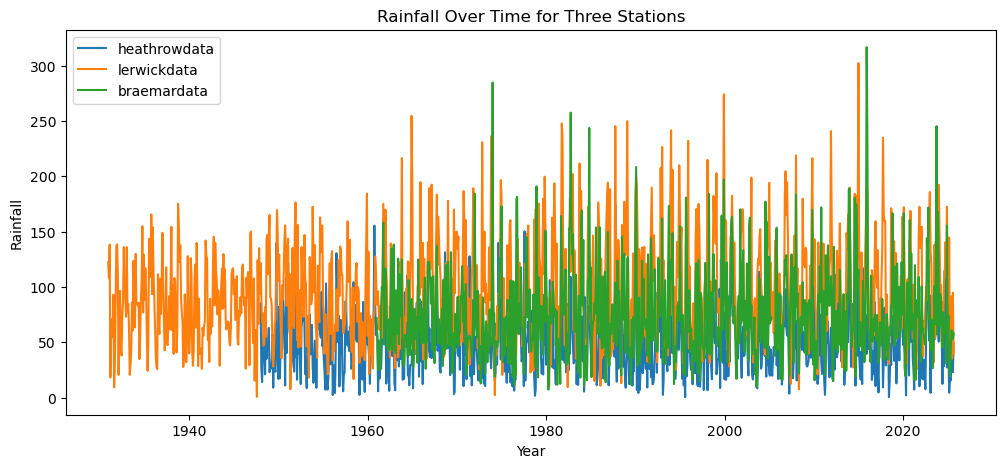

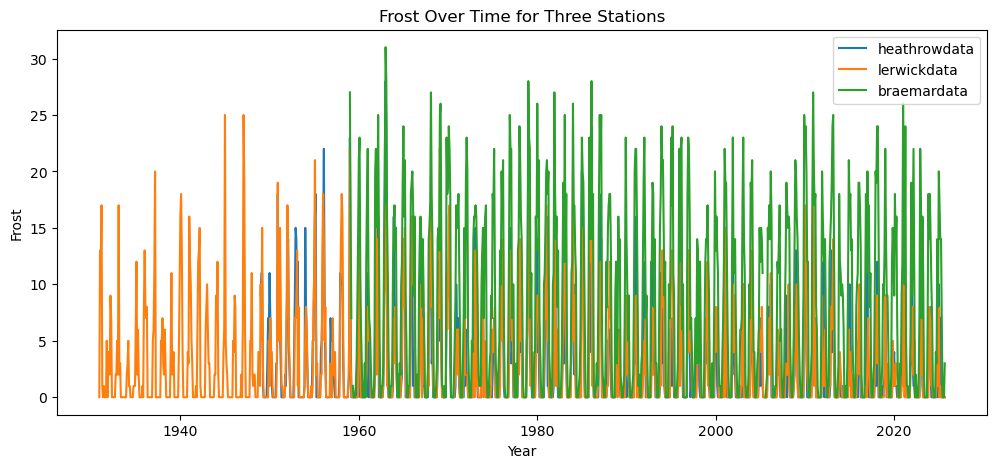

In [12]:
plot_variable(df_task1, "TMax", selected_stations)
plot_variable(df_task1, "Rainfall", selected_stations)
plot_variable(df_task1, "Frost", selected_stations)


## 3.3 Exploratory summary
The plots compare Heathrow, Lerwick and Braemar as examples of station records from different settings. They are descriptive views rather than formal evidence of causation or a representative sample of every UK region.

Maximum temperature generally rises over time in the three displayed records, although the apparent rate differs by station. Rainfall remains highly variable, so its long-term direction is less visually clear. Frost counts appear lower in later parts of the displayed records, particularly at Braemar, but missing observations and strong seasonality limit conclusions from the plots alone.

These patterns motivate the formal temperature modelling and exploratory frost analysis that follow.

# 4 Seasonal maximum-temperature trend model

## 4.1 Prepare seasonal predictors

- We need a helper that:
  - filters one station
  - sorts by time
  - creates t_months and seasonal terms.

In [13]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

def prepare_station_tmax(weather, station_file):
    """
    Select one station and add time + seasonal predictors for TMax regression.
    """
    sub = weather[weather["station_file"] == station_file].copy()
    
    # Drop rows where TMax is missing
    sub = sub.dropna(subset=["TMax"])
    
    # Sort by time
    sub = sub.sort_values(["Year", "Month"])
    
    # Time in months since first observation at this station
    first_year = sub["Year"].iloc[0]
    first_month = sub["Month"].iloc[0]
    sub["t_months"] = (sub["Year"] - first_year) * 12 + (sub["Month"] - first_month)
    
    # Annual seasonal terms with period 12 months (T = 12)
    T = 12.0
    omega = 2 * np.pi / T
    sub["sin_term"] = np.sin(omega * sub["t_months"])
    sub["cos_term"] = np.cos(omega * sub["t_months"])
    
    return sub


In [14]:
heathrow = prepare_station_tmax(weather, "heathrowdata")
heathrow


,Year,Month,TMax,TMin,Frost,Rainfall,Sunshine,Status,station_file,t_months,sin_term,cos_term
14052,1948,1,8.9,3.3,NaN,85.0,NaN,Confirmed,heathrowdata,0,0.000000e+00,1.000000e+00
14053,1948,2,7.9,2.2,NaN,26.0,NaN,Confirmed,heathrowdata,1,5.000000e-01,8.660254e-01
14054,1948,3,14.2,3.8,NaN,14.0,NaN,Confirmed,heathrowdata,2,8.660254e-01,5.000000e-01
14055,1948,4,15.4,5.1,NaN,35.0,NaN,Confirmed,heathrowdata,3,1.000000e+00,6.123234e-17
14056,1948,5,18.1,6.9,NaN,57.0,NaN,Confirmed,heathrowdata,4,8.660254e-01,-5.000000e-01
...,...,...,...,...,...,...,...,...,...,...,...,...
14980,2025,5,21.1,10.1,0.0,15.4,225.5,Provisional,heathrowdata,928,8.660254e-01,-5.000000e-01
14981,2025,6,25.6,14.1,0.0,26.8,230.8,Provisional,heathrowdata,929,5.000000e-01,-8.660254e-01
14982,2025,7,25.8,15.8,0.0,48.4,190.3,Provisional,heathrowdata,930,7.937816e-14,-1.000000e+00
14983,2025,8,25.0,14.1,0.0,23.0,192.0,Provisional,heathrowdata,931,-5.000000e-01,-8.660254e-01


## 4.2 Fit the seasonal regression
In this section, I will fit a linear regression model for the monthly mean daily maximum temperature.
and then:

1. Examine the fit of the regression for example stations.
2. Use a residual bootstrap to obtain confidence intervals for the trend (rate of change) at all stations.
3. Use a residual bootstrap to obtain prediction intervals for TMax in August 2075 for at least two stations, and compare with historical August temperatures.

This is where you fit the model and examine the fit before performing any bootstrapping.

In [15]:
def fit_tmax_model(station_df):
    X = station_df[["t_months", "sin_term", "cos_term"]]
    X = sm.add_constant(X)  # adds intercept
    y = station_df["TMax"]
    
    model = sm.OLS(y, X).fit()
    return model

heathrow_model = fit_tmax_model(heathrow)

# Look at a text summary (optional but useful)
print(heathrow_model.summary())


                            OLS Regression Results                            
Dep. Variable:                   TMax   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     3438.
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:06:49   Log-Likelihood:                -1803.5
No. Observations:                 933   AIC:                             3615.
Df Residuals:                     929   BIC:                             3634.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.8244      0.110    126.099      0.0

### Heathrow model summary

The seasonal-linear model explains 91.7% of the observed monthly variation in Heathrow TMax. Much of this fit reflects the strong annual cycle captured by the sine and cosine terms, so the R² should not be interpreted as evidence for the time trend alone.

The fitted time coefficient is approximately 0.0026°C per month, equivalent to about 0.31°C per decade. The conventional OLS output reports p < 0.001, but those standard errors assume an error structure that is not fully supported by the time series.

The Durbin–Watson statistic of 1.41 indicates remaining positive serial correlation. The model is useful as a descriptive seasonal-trend model, but uncertainty estimates based on independent errors should be treated cautiously.


## 4.3 Examine model fit

In [16]:
def plot_regression_fit(df, model, station_name):

    fitted = model.fittedvalues
    residuals = model.resid
    time = df["t_months"]

    plt.figure(figsize=(15, 4))

    # ---- Plot 1: Observed vs Fitted ----
    plt.subplot(1, 3, 1)
    plt.scatter(fitted, df["TMax"], s=8)
    plt.plot(fitted, fitted, color="red")
    plt.xlabel("Fitted")
    plt.ylabel("Observed TMax")
    plt.title(f"{station_name}: Observed vs Fitted")

    # ---- Plot 2: Residuals vs Fitted ----
    plt.subplot(1, 3, 2)
    plt.scatter(fitted, residuals, s=8)
    plt.axhline(0, color="red")
    plt.xlabel("Fitted")
    plt.ylabel("Residuals")
    plt.title(f"{station_name}: Residuals vs Fitted")

    # ---- Plot 3: Residuals vs Time ----
    plt.subplot(1, 3, 3)
    plt.scatter(time, residuals, s=8)
    plt.axhline(0, color="red")
    plt.xlabel("Time (months)")
    plt.ylabel("Residuals")
    plt.title(f"{station_name}: Residuals vs Time")

    plt.tight_layout()
    plt.show()


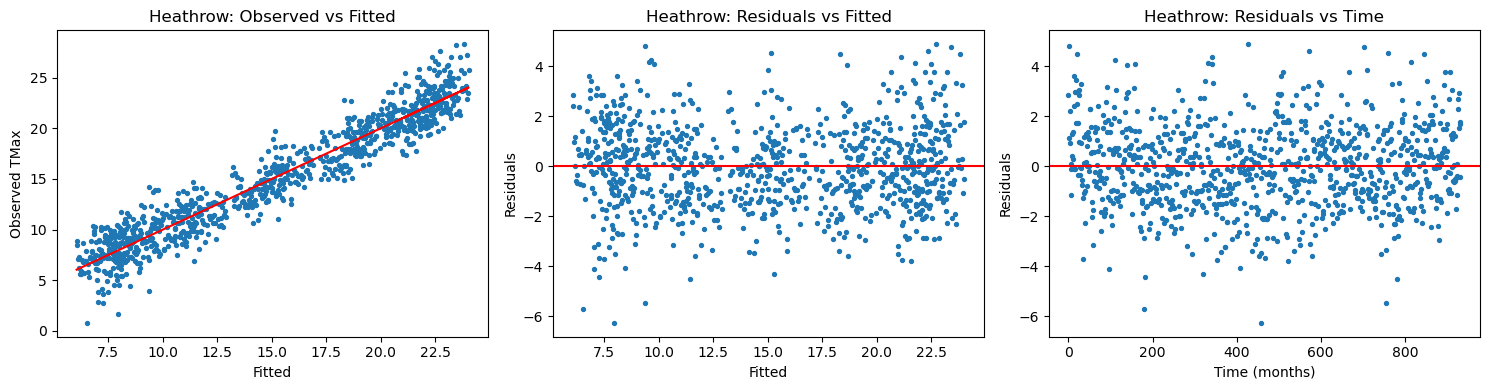

In [17]:
#Diagnostic plot 
plot_regression_fit(heathrow, heathrow_model, "Heathrow")

### Heathrow diagnostic interpretation

The observed-versus-fitted plot shows that the model captures the dominant annual temperature cycle. The residual-versus-fitted plot does not show a pronounced funnel shape, suggesting that variance is reasonably stable across the fitted range.

Residuals remain temporally structured, however. The Durbin–Watson statistic and residual-over-time plot indicate positive serial correlation that the linear trend and annual sine/cosine terms do not fully remove. Consequently, the fitted slope is informative as a descriptive trend, but conventional OLS inference and independent-residual bootstrapping may understate uncertainty.


## 4.4 Residual-bootstrap trend interval for Heathrow

In [18]:
def bootstrap_trend_ci(model, B=2000, random_state=0):
    rng = np.random.default_rng(random_state)

    X = model.model.exog              # design matrix (const, t_months, sin, cos)
    fitted = model.fittedvalues.values
    resid = model.resid.values
    n = len(resid)

    # index of the trend coefficient (t_months) in params
    beta_names = list(model.params.index)
    idx_trend = beta_names.index("t_months")

    boot_trend = np.empty(B)

    for b in range(B):
        # 3. resample residuals with replacement
        boot_resid = rng.choice(resid, size=n, replace=True)

        # 4. new y* = fitted + resampled residuals
        y_boot = fitted + boot_resid

        # 5. refit regression on same X
        boot_model = sm.OLS(y_boot, X).fit()

        # store trend coefficient
        boot_trend[b] = boot_model.params[idx_trend]

    # convert from °C per month to °C per decade
    boot_trend_decade = boot_trend * 12 * 10

    # point estimate and 95% CI
    est = boot_trend_decade.mean()
    ci_low, ci_high = np.percentile(boot_trend_decade, [2.5, 97.5])

    return est, ci_low, ci_high, boot_trend_decade


In [19]:
heathrow_est, heathrow_low, heathrow_high, heathrow_boot = bootstrap_trend_ci(heathrow_model)

heathrow_est, (heathrow_low, heathrow_high)


(np.float64(0.3132231690393048),
 (np.float64(0.2656956637594934), np.float64(0.3599236613239545)))

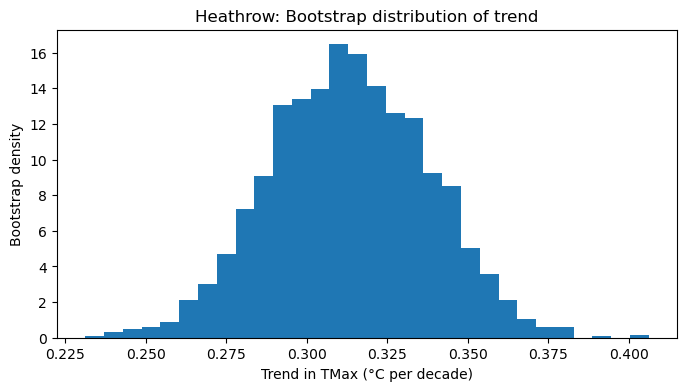

In [20]:
#You can also make a quick histogram of the bootstrap distribution if you like:
plt.hist(heathrow_boot, bins=30, density=True)
plt.xlabel("Trend in TMax (°C per decade)")
plt.ylabel("Bootstrap density")
plt.title("Heathrow: Bootstrap distribution of trend")
plt.show()


### Heathrow bootstrap interpretation

Under the original independent-residual resampling procedure, Heathrow's trend distribution is centred at approximately 0.313°C per decade, with a percentile interval of 0.266–0.360°C per decade.

The interval is entirely above zero under these assumptions. It should be interpreted as a conditional residual-bootstrap interval rather than an autocorrelation-robust confidence interval. A moving-block bootstrap, HAC standard errors or an explicit time-series error model would provide a stronger assessment of uncertainty.


## 4.5 Compare trend intervals across all stations

This step is to loop over each station file name and apply:
- prepare_station_tmax()
- fit_tmax_model()
- bootstrap_trend_ci()
- Store the estimated trend + CI

This produces one row per station. Then I will sort, plot, and interpret.

In [21]:
#(A) Loop over all stations
station_results = []

for st in sorted(weather["station_file"].unique()):
    sub = prepare_station_tmax(weather, st)
    
    # Skip stations with very few TMax values
    if len(sub) < 100:
        continue

    model = fit_tmax_model(sub)
    est, low, high, _ = bootstrap_trend_ci(model, B=2000, random_state=0)

    station_results.append({
        "station_file": st,
        "trend_decade": est,
        "ci_low": low,
        "ci_high": high
    })

trend_ci_df = pd.DataFrame(station_results)
trend_ci_df


,station_file,trend_decade,ci_low,ci_high
0,aberporthdata,0.119908,0.086238,0.153428
1,armaghdata,0.059853,0.046027,0.073212
2,ballypatrickdata,0.237767,0.191115,0.284196
3,bradforddata,0.149764,0.126278,0.174105
4,braemardata,0.232525,0.173863,0.289105
5,cambornedata,0.304040,0.233981,0.375893
6,cambridgedata,0.343576,0.283352,0.404540
7,cardiffdata,0.408207,0.325681,0.491534
8,chivenordata,0.190585,0.141795,0.240934
9,cwmystwythdata,0.230904,0.151886,0.308052


In [22]:
#(B) Sort them to see patterns
trend_ci_df_sorted = trend_ci_df.sort_values("trend_decade")
trend_ci_df_sorted


,station_file,trend_decade,ci_low,ci_high
1,armaghdata,0.059853,0.046027,0.073212
28,southamptondata,0.063493,0.045231,0.082228
16,lerwickdata,0.067141,0.045403,0.089523
31,tireedata,0.067431,0.047420,0.086805
29,stornowaydata,0.071035,0.058848,0.082491
20,nairndata,0.089071,0.049999,0.127646
22,oxforddata,0.098080,0.083746,0.112676
11,durhamdata,0.104647,0.087160,0.121677
18,lowestoftdata,0.111071,0.076544,0.145521
13,eskdalemuirdata,0.114067,0.090947,0.137060


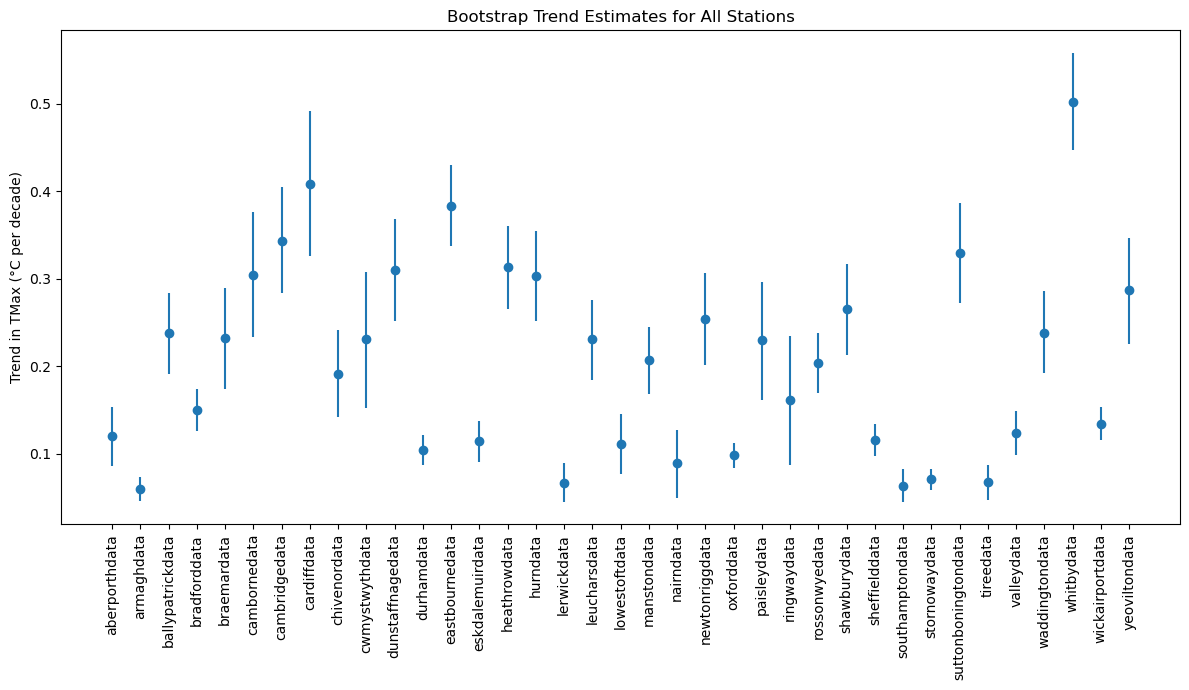

In [23]:
#(C) Optional: Plot with CIs
plt.figure(figsize=(12, 7))
plt.errorbar(
    trend_ci_df_sorted.index,
    trend_ci_df_sorted["trend_decade"],
    yerr=[trend_ci_df_sorted["trend_decade"] - trend_ci_df_sorted["ci_low"],
          trend_ci_df_sorted["ci_high"] - trend_ci_df_sorted["trend_decade"]],
    fmt="o"
)
plt.xticks(trend_ci_df_sorted.index, trend_ci_df_sorted["station_file"], rotation=90)
plt.ylabel("Trend in TMax (°C per decade)")
plt.title("Bootstrap Trend Estimates for All Stations")
plt.tight_layout()
plt.show()


### All-station trend interpretation

All 37 fitted station slopes are positive in the original seasonal-linear analysis. Under the same independent-residual bootstrap procedure, every recorded percentile interval lies above zero. Estimated slopes range from approximately 0.060°C to 0.502°C per decade.

These results show a consistent positive association between time and monthly maximum temperature within the fitted station models. Direct geographical comparisons require caution because stations cover different historical periods, some recent observations are provisional, and the source data are not adjusted for every site or instrumentation change.

The present analysis does not formally test whether latitude, altitude, urbanisation or coastal proximity explain differences between station slopes. Those relationships should therefore be treated as questions for further analysis rather than conclusions from this model.


## 4.6 August 2075 model extrapolation

- Choose at least two stations (e.g., Heathrow and Lerwick)
- Fit the same regression model
- Compute a prediction for August 2075 (using the regression model and including seasonal sine/cos terms)
- Use residual bootstrap to obtain a predictive interval
- Compare the predicted future August temperatures with the historical August TMax

In [24]:
#Step 1 — Function to compute predictors for August 2075
def make_future_predictors(sub, year=2075, month=8):
   
    first_year = sub["Year"].iloc[0]
    first_month = sub["Month"].iloc[0]

    # future time index in months
    t_future = (year - first_year) * 12 + (month - first_month)

    # seasonal terms
    omega = 2 * np.pi / 12
    sin_future = np.sin(omega * t_future)
    cos_future = np.cos(omega * t_future)

    # return as a design row (including constant)
    X_future = np.array([1, t_future, sin_future, cos_future])
    return X_future


In [25]:
#Step 2 — Residual bootstrap predictive interval
def bootstrap_predictive_interval(sub, model, B=2000, year=2075, month=8):

    rng = np.random.default_rng(0)

    X = model.model.exog
    fitted = model.fittedvalues.values
    resid = model.resid.values
    n = len(resid)

    # future predictor row
    X_future = make_future_predictors(sub, year, month)
    
    preds = np.empty(B)

    for b in range(B):
        # bootstrap residuals
        boot_resid = rng.choice(resid, size=n, replace=True)
        y_boot = fitted + boot_resid

        # refit bootstrap model
        boot_model = sm.OLS(y_boot, X).fit()

        # sample one residual for future prediction
        eps_star = rng.choice(resid)
        preds[b] = float(boot_model.predict(X_future)[0] + eps_star)

    # predictive interval
    pi_low, pi_high = np.percentile(preds, [2.5, 97.5])
    pred_mean = preds.mean()

    return pred_mean, pi_low, pi_high, preds


In [26]:
#Step 3 — Run it for two stations
heathrow = prepare_station_tmax(weather, "heathrowdata")
heathrow_model = fit_tmax_model(heathrow)

heathrow_pred_mean, heathrow_pi_low, heathrow_pi_high, heathrow_preds = \
    bootstrap_predictive_interval(heathrow, heathrow_model)

heathrow_pred_mean, (heathrow_pi_low, heathrow_pi_high)


(np.float64(24.856950581815507),
 (np.float64(21.695505530285963), np.float64(28.25157457451583)))

### Heathrow summary

- Conditional August 2075 model extrapolation: 24.86°C
- Residual-bootstrap interval: 21.70–28.25°C


In [27]:
lerwick = prepare_station_tmax(weather, "lerwickdata")
lerwick_model = fit_tmax_model(lerwick)

lerwick_pred_mean, lerwick_pi_low, lerwick_pi_high, lerwick_preds = \
    bootstrap_predictive_interval(lerwick, lerwick_model)

lerwick_pred_mean, (lerwick_pi_low, lerwick_pi_high)


(np.float64(14.606844774121962),
 (np.float64(12.53837463037211), np.float64(16.650740994692704)))

### Lerwick summary

- Conditional August 2075 model extrapolation: 14.61°C
- Residual-bootstrap interval: 12.54–16.65°C


### Interpreting the extrapolation intervals

The fitted seasonal-linear model extrapolates an August 2075 TMax of approximately 24.86°C for Heathrow and 14.61°C for Lerwick. These values extend a constant linear trend far beyond the observed records and are conditional on the model specification and residual-resampling assumptions.

Heathrow's extrapolated mean is above its historical August average of 22.64°C, but the interval of 21.70–28.25°C overlaps the observed August range of 18.8–27.0°C. Lerwick's extrapolated mean of 14.61°C is close to its historical August average of 14.43°C, and its interval of 12.54–16.65°C lies almost entirely within the observed range of 12.6–17.2°C.

The two stations demonstrate how the fitted model behaves under long-range extrapolation; they do not constitute scenario-based climate projections or establish a general north-south pattern.


## 4.7 Compare extrapolations with historical August values

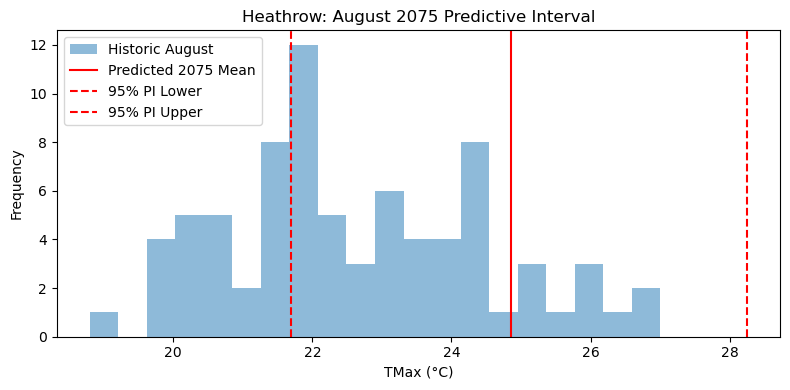

In [28]:
plt.hist(
    heathrow[heathrow["Month"] == 8]["TMax"],
    bins=20,
    alpha=0.5,
    label="Historic August"
)

# Predicted mean
plt.axvline(heathrow_pred_mean, color="red", label="Predicted 2075 Mean")

# Predictive interval bounds
plt.axvline(heathrow_pi_low, color="red", linestyle="--", label="95% PI Lower")
plt.axvline(heathrow_pi_high, color="red", linestyle="--", label="95% PI Upper")

plt.xlabel("TMax (°C)")                  # X-axis label
plt.ylabel("Frequency")                  # Y-axis label
plt.title("Heathrow: August 2075 Predictive Interval")
plt.legend()
plt.tight_layout()
plt.show()


### Heathrow comparison

Heathrow's extrapolated August 2075 mean of approximately 24.86°C is about 2.2°C above the historical August average of 22.64°C. The residual-bootstrap interval of 21.70–28.25°C overlaps the historical August range of 18.8–27.0°C, although its upper bound extends beyond the largest value in this snapshot.

This is consistent with the model's positive fitted trend, but the result remains a long-range linear extrapolation and does not represent a scenario-based climate forecast.


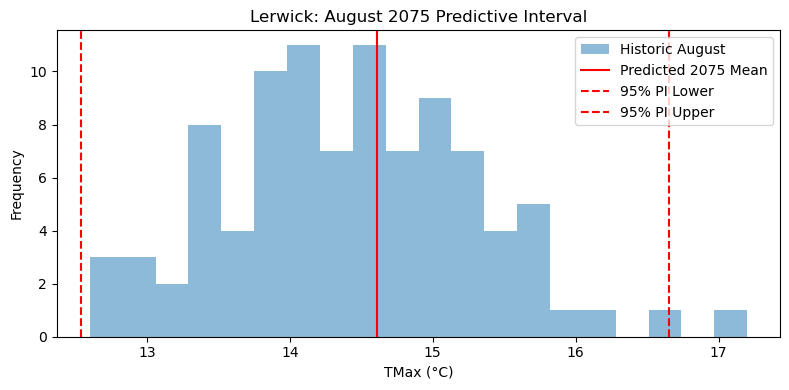

In [29]:
plt.hist(
    lerwick[lerwick["Month"] == 8]["TMax"],
    bins=20,
    alpha=0.5,
    label="Historic August"
)

# Predicted mean
plt.axvline(lerwick_pred_mean, color="red", label="Predicted 2075 Mean")

# Predictive interval bounds
plt.axvline(lerwick_pi_low, color="red", linestyle="--", label="95% PI Lower")
plt.axvline(lerwick_pi_high, color="red", linestyle="--", label="95% PI Upper")

plt.xlabel("TMax (°C)")                  # X-axis label
plt.ylabel("Frequency")                  # Y-axis label
plt.title("Lerwick: August 2075 Predictive Interval")
plt.legend()
plt.tight_layout()
plt.show()


### Lerwick comparison

Lerwick's extrapolated August 2075 mean of approximately 14.61°C is close to the historical August average of 14.43°C. The residual-bootstrap interval of 12.54–16.65°C falls almost entirely within the observed August range of 12.6–17.2°C.

This illustrates the relatively small fitted slope for Lerwick within the selected model. Explaining that difference would require additional variables and analysis; the station record alone does not establish the influence of maritime location or other causal factors.


# 5 Exploratory frost-occurrence analysis

## 5.1 Initial decade association for Heathrow

- 1A — Prepare frost dataset for one station (I choose "heathrowdata" first).
- 1B — Create Frost/No-Frost column
- 1C — Create a decade column
- 1D — Make a crosstab
- 1E — Run chi-square independence test

These tests:

- H₀: Frost occurrence is independent of decade
- H₁: Frost occurrence depends on decade (i.e., the pattern is changing over time)

### Prepare the decade-by-frost table
- 1A — Prepare frost dataset for one station (I choose "heathrowdata" first).
- 1B — Create Frost/No-Frost column
- 1C — Create a decade column
- 1D — Make a crosstab

In [30]:
import pandas as pd
from scipy.stats import chi2_contingency

def prepare_frost_table(weather, station_file):
    """
    Prepares a decade × frost/no-frost crosstab for chi-square testing.
    """
    df = weather[weather["station_file"] == station_file].copy()
    
    # Drop missing frost values
    df = df.dropna(subset=["Frost"])
    
    # Frost category (required to make chi-square valid)
    df["FrostCat"] = df["Frost"].apply(lambda x: "Frost" if x > 0 else "No Frost")
    
    # Decade category
    df["Decade"] = (df["Year"] // 10) * 10
    
    # Crosstab
    table = pd.crosstab(df["Decade"], df["FrostCat"])
    
    return table

# ---- Run for Heathrow ----
heathrow_table = prepare_frost_table(weather, "heathrowdata")
heathrow_table


FrostCat,Frost,No Frost
Decade,,
1940,7,5
1950,60,60
1960,59,61
1970,58,62
1980,57,63
1990,56,64
2000,49,71
2010,49,71
2020,28,41


### Run the chi-square test

In [31]:
chi2, p, dof, expected = chi2_contingency(heathrow_table)

chi2, p


(np.float64(5.7801135779627915), np.float64(0.6718469240025425))

### Initial chi-square interpretation
The initial all-month decade table gives χ² ≈ 5.78 and p ≈ 0.67. At the conventional 0.05 threshold, this test does not reject independence between decade and the binary monthly frost indicator.

This is an exploratory result, not evidence that frost occurrence was stable. Combining all months retains strong seasonal structure, while a non-significant result may reflect limited sensitivity as well as a genuinely weak association. The winter-only analysis below provides a more focused comparison.

## 5.2 Winter-decade and whole-year tests

### 5.2.1 Winter decade-by-frost test


This section explores whether the probability that a month contains at least one frost day is associated with time. Heathrow is used to demonstrate the method before it is repeated across all 37 stations.

*What this analysis does:*

- Select one weather station (Heathrow).
This allows us to demonstrate the method clearly before generalizing to all 37 stations.

- Convert frost counts into a binary category:

    - 1 = at least one frost day
    - 0 = zero frost days

      This creates a categorical outcome suitable for a contingency table, although it discards information about the number of frost days.

- Restrict the data to winter months (December, January, February).
This reduces, but does not eliminate, seasonal differences.

- Group observations by decade.
This pools observations into larger time groups, but sparse expected cells can still make the chi-square approximation unreliable.

- Create a contingency table:

        - Rows → decade
        - Columns → frost vs no frost

- Run a chi-squared test of independence.
This tests the question:
**“Is winter frost occurrence independent of decade?”**
  
A small unadjusted p-value (< 0.05) would flag a possible association for further investigation; it would not establish a trend direction or cause.

The following code implements these steps for the Heathrow station:

In [32]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency


# 1 — Select Heathrow station
station = "heathrowdata"
df = weather[weather["station_file"] == station].copy()

# 2 — Clean frost column
df = df.dropna(subset=["Frost"])  # remove missing frost values

# 3 — Create Frost_cat (0 = no frost, 1 = frost)
def add_frost_category(df):
    df = df.copy()
    df["Frost_cat"] = np.where(df["Frost"] > 0, 1, 0)
    return df

df = add_frost_category(df)

# 4 — Filter to WINTER months only (Dec, Jan, Feb)
winter = df[df["Month"].isin([12, 1, 2])].copy()

# 5 — Create decade variable
winter["decade"] = (winter["Year"] // 10) * 10

# 6 — Build Crosstab (Decade × Frost_cat)
table_decade = pd.crosstab(winter["decade"], winter["Frost_cat"])
print("Crosstab: Decade × Frost (Winter)")
print(table_decade)

# 7 — Run Chi-Square Test
chi2, p, dof, expected = chi2_contingency(table_decade)

print("\nChi-Square Test Results:")
print("Chi2 =", chi2)
print("p-value =", p)
print("Degrees of freedom =", dof)

Crosstab: Decade × Frost (Winter)
Frost_cat  0   1
decade          
1940       0   3
1950       0  30
1960       1  29
1970       1  29
1980       0  30
1990       1  29
2000       2  28
2010       2  28
2020       1  16

Chi-Square Test Results:
Chi2 = 4.3853780250839085
p-value = 0.8207881273331952
Degrees of freedom = 8


### Heathrow winter-test interpretation

The chi-square test for the winter-only crosstab (Decade × Frost occurrence) gives
- χ² = 4.39,
- df = 8,
- p = 0.821.

The unadjusted p-value is above 0.05, so this test does not reject independence between decade and the binary winter frost indicator at Heathrow. It does not prove that frost occurrence was stable.

The asymptotic chi-square assumptions are also weak here: the minimum expected count is approximately 0.10, and 55.6% of expected cells are below 5. The p-value should therefore be treated as descriptive rather than as reliable confirmatory inference.

### 5.2.2 Whole-year year-by-frost test

For this first analysis, we use all months of the year, which allows us to build a contingency table of:

**Year × Frost occurrence**

This crosstab allows us to test the hypothesis:

- H₀ (independence): The occurrence of frost does not depend on the year.
- H₁ (dependence): The binary monthly frost indicator is associated with year.

The chi-square test is used here as an exploratory screen. Because each year contributes only a small number of monthly observations, the resulting contingency table is likely to contain sparse expected counts.

The following code prepares the frost category, builds the crosstab, and performs the chi-square test for Heathrow.

In [33]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Select Heathrow station
station = "heathrowdata"
df = weather[weather["station_file"] == station].copy()

# 2. Remove missing frost values
df = df.dropna(subset=["Frost"])

# 3. Create Frost binary category (0 = no frost, 1 = frost)
def add_frost_category(df):
    df = df.copy()
    df["Frost_cat"] = np.where(df["Frost"] > 0, 1, 0)
    return df

df = add_frost_category(df)

# 4. Crosstab: Year × Frost (Whole Year)
table_year = pd.crosstab(df["Year"], df["Frost_cat"])
print("Crosstab — Year × Frost (Whole Year):")
display(table_year)

# 5. Chi-Square test
chi2, p, dof, expected = chi2_contingency(table_year)

print("\nChi-square results (Year × Frost):")
print(f"Chi2 statistic = {chi2}")
print(f"p-value        = {p}")
print(f"Degrees of freedom = {dof}")

Crosstab — Year × Frost (Whole Year):


Frost_cat,0,1
Year,,
1949,5,7
1950,5,7
1951,5,7
1952,5,7
1953,8,4
...,...,...
2021,6,6
2022,7,5
2023,7,5



Chi-square results (Year × Frost):
Chi2 statistic = 23.71644734968242
p-value        = 0.9999999987418811
Degrees of freedom = 76


### Heathrow whole-year interpretation

The chi-square test for independence between year and frost occurrence at Heathrow gives:

- Chi² = 23.72
- p-value ≈ 1.00
- df = 76

The reported p-value is above 0.05, so the test does not reject independence. However, at least one expected cell is below 5 (minimum ≈ 4.13), and the table has many year categories with few observations per row. The chi-square approximation is therefore questionable.

This result should not be interpreted as proof that Heathrow frost occurrence was stable or that no long-term trend exists.

## 5.3 Repeat the tests across all stations

As an exploratory screen, I evaluated whether a binary monthly frost indicator is associated with time.

Because frost strongly depends on the time of year, the winter-only comparison is more interpretable than pooling all seasons. The whole-year test is retained as a secondary comparison.

I therefore used:

Winter months only (Dec–Feb)
→ Crosstab: Decade × Frost (binary)
→ Chi-square test of independence

Whole Year (all months)
→ Crosstab: Year × Frost (binary)
→ Chi-square test of independence

Frost counts were converted to a binary category:
- 1 = at least one frost day in the month
- 0 = zero frost days

After testing Heathrow individually, I repeated the same screening procedure for all 37 weather stations. Raw p-values are shown in the saved outputs; they require assumption checks and multiple-testing adjustment before inferential interpretation.

*The results_df table will contain:*
- Station name
- p-value for Decade × Frost (Winter)
- p-value for Year × Frost (Whole Year)

In [34]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

def frost_chi_square_for_station(df):
    """
    Run both chi-square tests (Decade × Frost in Winter, and Year × Frost)
    for a single station's DataFrame.
    Returns a dictionary with results.
    """
    # Remove missing frost values
    df = df.dropna(subset=["Frost"]).copy()

    # Frost binary category
    df["Frost_cat"] = np.where(df["Frost"] > 0, 1, 0)

    # -----------------------------
    # Test 1: DECADE × FROST (WINTER ONLY)
    # -----------------------------
    winter = df[df["Month"].isin([12, 1, 2])].copy()
    winter["Decade"] = (winter["Year"] // 10) * 10
    table_decade = pd.crosstab(winter["Decade"], winter["Frost_cat"])

    # Handle small/empty tables
    if table_decade.shape[0] > 1:
        chi2_d, p_d, dof_d, _ = chi2_contingency(table_decade)
    else:
        chi2_d, p_d, dof_d = np.nan, np.nan, np.nan

    # -----------------------------
    # Test 2: YEAR × FROST (WHOLE YEAR)
    # -----------------------------
    table_year = pd.crosstab(df["Year"], df["Frost_cat"])

    if table_year.shape[0] > 1:
        chi2_y, p_y, dof_y, _ = chi2_contingency(table_year)
    else:
        chi2_y, p_y, dof_y = np.nan, np.nan, np.nan

    return {
        "chi2_decade": chi2_d,
        "p_decade": p_d,
        "chi2_year": chi2_y,
        "p_year": p_y
    }


In [35]:
#Run This Function for ALL 37 Stations
stations = weather["station_file"].unique()
results = []

for st in stations:
    df_st = weather[weather["station_file"] == st]
    res = frost_chi_square_for_station(df_st)
    res["station"] = st
    results.append(res)

results_df = pd.DataFrame(results)
results_df


,chi2_decade,p_decade,chi2_year,p_year,station
0,19.868399,0.005861,43.497826,0.991003,aberporthdata
1,17.976156,0.325295,52.456461,1.000000,armaghdata
2,6.526534,0.366857,33.158025,0.997381,ballypatrickdata
3,5.037665,0.956709,33.320474,1.000000,bradforddata
4,0.000000,1.000000,25.889087,0.999998,braemardata
5,8.398299,0.135608,41.203481,0.710490,cambornedata
6,1.628423,0.977528,19.466737,1.000000,cambridgedata
7,4.823970,0.437739,12.387782,1.000000,cardiffdata
8,5.570719,0.233583,22.106956,0.986506,chivenordata
9,0.000000,1.000000,25.820317,0.999123,cwmystwythdata


In [36]:

# Summarise the Chi-Square Results Across All Stations

summary = pd.DataFrame({
    "Stations Showing Change (Decade Test)": [(results_df["p_decade"] < 0.05).sum()],
    "Stations Showing Change (Year Test)": [(results_df["p_year"] < 0.05).sum()],
    "Total Stations": [len(results_df)]
})

summary["% Change (Decade Test)"] = summary["Stations Showing Change (Decade Test)"] / summary["Total Stations"]
summary["% Change (Year Test)"] = summary["Stations Showing Change (Year Test)"] / summary["Total Stations"]
summary




,Stations Showing Change (Decade Test),Stations Showing Change (Year Test),Total Stations,% Change (Decade Test),% Change (Year Test)
0,5,0,37,0.135135,0.0


### All-station frost interpretation
The saved summary reports five of 37 winter decade-by-frost tests with raw p-values below 0.05. Because 37 stations were tested, these raw flags were audited for multiple comparisons: only Valley and Stornoway remain below 0.05 using either Bonferroni correction or Benjamini–Hochberg false-discovery-rate control. The tests identify association only; they do not by themselves show that frost declined.

The chi-square assumptions substantially limit even this adjusted result. Thirty-five of 37 winter tables contain at least one expected cell below 5, and five tables contain only one observed frost category. Consequently, the asymptotic p-values should be treated as exploratory signals rather than confirmatory evidence.

The whole-year screen reports no raw p-values below 0.05, but all 37 Year × Frost tables contain at least one expected cell below 5. These non-significant values cannot establish stability or rule out gradual change.

Overall, this section identifies a small number of station-level signals for follow-up. It does not provide robust nationwide evidence about the direction, magnitude or cause of changes in frost occurrence.

## 5.4 Visualise station-level p-values

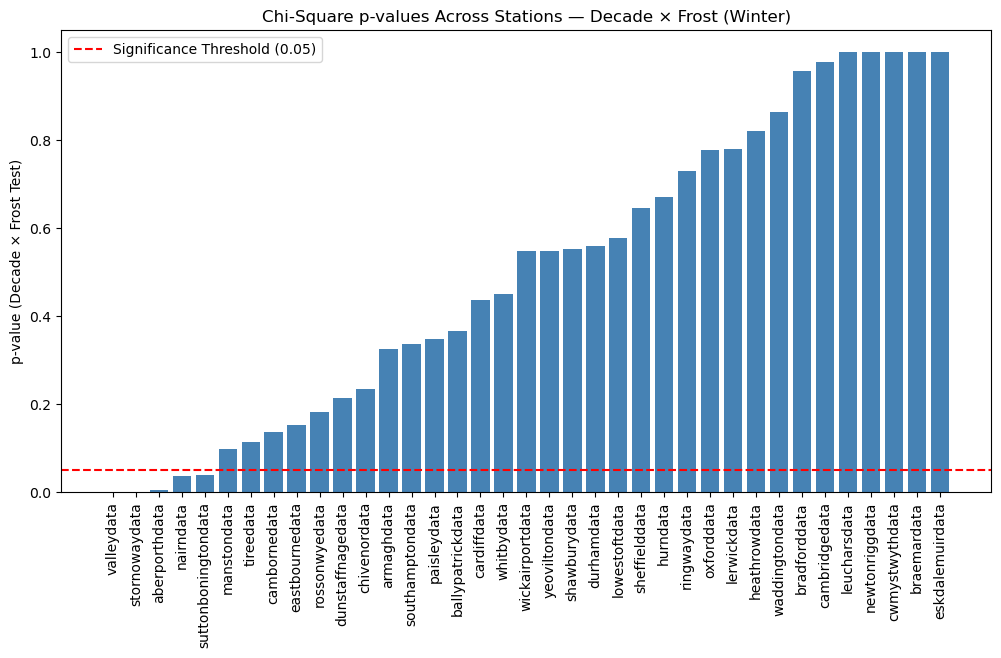

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Sort by p-value for a cleaner plot
results_sorted = results_df.sort_values("p_decade")

plt.bar(results_sorted["station"], results_sorted["p_decade"], color="steelblue")
plt.axhline(0.05, color="red", linestyle="--", label="Significance Threshold (0.05)")

plt.xticks(rotation=90)
plt.ylabel("p-value (Decade × Frost Test)")
plt.title("Chi-Square p-values Across Stations — Decade × Frost (Winter)")
plt.legend()
plt.show()


### Winter-decade p-value plot
The chart displays raw chi-square p-values for the 37 winter Decade × Frost screens; the dashed line is the unadjusted 0.05 threshold. Five stations fall below that line, while only Valley and Stornoway remain below 0.05 after Bonferroni or Benjamini–Hochberg correction. Because expected counts are sparse for 35 stations, the plot is useful for prioritising follow-up analysis but not for confirming station-level or nationwide change.

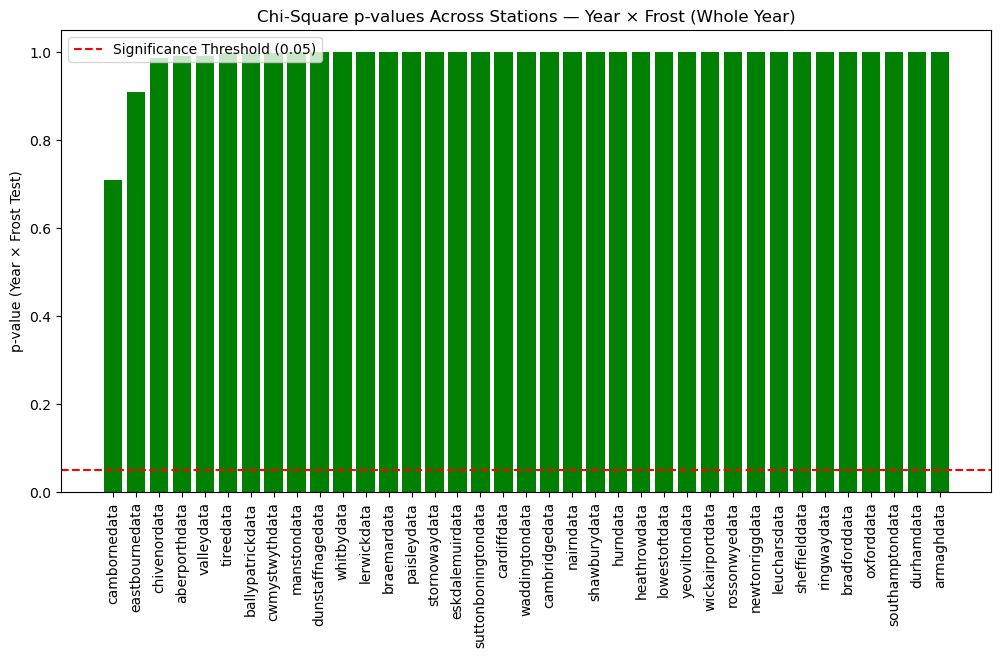

In [38]:
plt.figure(figsize=(12, 6))

results_sorted_y = results_df.sort_values("p_year")

plt.bar(results_sorted_y["station"], results_sorted_y["p_year"], color="green")
plt.axhline(0.05, color="red", linestyle="--", label="Significance Threshold (0.05)")

plt.xticks(rotation=90)
plt.ylabel("p-value (Year × Frost Test)")
plt.title("Chi-Square p-values Across Stations — Year × Frost (Whole Year)")
plt.legend()
plt.show()


### Whole-year p-value plot

This plot displays the p-values for chi-square tests assessing whether annual frost occurrence is independent of year for each station. 

No station has a raw p-value below 0.05 in this screen. However, every Year × Frost table contains at least one expected cell below 5, so the asymptotic chi-square p-values are not dependable for confirmatory inference. The plot therefore does not establish that annual frost occurrence was stable; it shows only that this particular sparse-table procedure did not flag a station.

# 6 Evidence, limitations and next steps

## 6.1 Temperature-trend evidence
The clearest pattern in this analysis is the positive fitted maximum-temperature slope at all 37 stations. Under the original independent-residual bootstrap, every recorded percentile interval is above zero. These results describe the fitted seasonal-linear models, but serial correlation—illustrated by Heathrow's Durbin–Watson statistic of 1.41—means the intervals should not be presented as autocorrelation-robust inference.

The August 2075 values are long-range linear extrapolations rather than scenario-based climate projections. Heathrow's extrapolated interval overlaps its historical August range, while Lerwick's lies almost entirely within its historical range; these estimates therefore illustrate model behaviour rather than validate a future forecast.

## 6.2 Limits of causal interpretation

The station records and models quantify associations with time; they do not identify causal mechanisms. Explaining differences among stations would require variables such as latitude, altitude, coastal exposure, urbanisation, station moves and instrumentation changes, together with a design suited to causal attribution.

The frost chi-square screens are especially limited by sparse expected counts and multiple testing. Their non-significant results cannot be used to infer winter stability, and their low p-values do not establish a climatic cause.

## 6.3 Geographic variation

The fitted maximum-temperature slopes vary among stations, but this analysis does not establish a general geographic pattern or explain the differences. The frost screen produced five raw p-values below 0.05 and two after multiple-testing correction, with widespread assumption violations. Rainfall and sunshine also vary substantially across the descriptive plots.

A defensible geographic comparison would model station characteristics explicitly and account for record length, missingness, serial dependence and possible changes in measurement conditions.

## 6.4 Further work

Several improvements could strengthen and extend this analysis:

**1- Incorporate external drivers** such as altitude, distance to coast, or latitude to explain regional differences in warming.

**2- Apply time-series models**, such as models with autocorrelated errors or generalized additive models, to capture dependence and possible non-linearity in temperature.

**3- Analyse extreme events** (e.g., heatwaves, heavy rainfall days), which may reveal stronger climate-driven changes than monthly averages.

**4- Reanalyse frost occurrence** with a binomial or logistic time-trend model that includes month or season, or use a count model for frost days. Where sparse categories remain, consider exact, permutation or Monte Carlo inference and control the false discovery rate across stations. Daily data would support a more detailed analysis.

**5- Cluster stations by climate similarity** to explore whether groups of stations respond similarly over time.

Overall, the notebook documents positive fitted maximum-temperature trends and an exploratory frost screen. Stronger uncertainty modelling and explicit station-level covariates are needed before making robust geographic, frost or causal claims.